# Practice Activity 6.1: Writing Functions

Completed solutions for every exercise in the supplied notebook. Run the cells from top to bottom. The examples that intentionally fail are caught and explained so the notebook can finish executing.

The penguin examples use the packaged Palmer Penguins data. See the [course section on scope and dynamic lookup](https://ds-ml-with-python.github.io/Course-Textbook/05-function_writing.html#nested-environments-and-scope).

In [1]:
# Install the repository's requirements before opening this notebook:
# python -m pip install -r requirements.txt

import numpy as np
import pandas as pd
from sys import exit
from numbers import Number
from palmerpenguins import load_penguins
from plotnine import ggplot, aes, geom_point, geom_bar

/Users/nick_ramel/Downloads/msbawork/.pa6-venv/lib/python3.14/site-packages/palmerpenguins/penguins.py:2: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  import pkg_resources


0\. Complete the [**check-in** from Section 6.3.2](https://ds-ml-with-python.github.io/Course-Textbook/05-function_writing.html#nested-environments-and-scope): Write a custom function that does the following:

Limit the penguins dataset to a user-chosen species and/or island.
Makes a scatterplot of the penguin bill length and depth.
Try writing a version of this function using dynamic lookup, and a version where everything the function needs is passed in directly

The dynamic-lookup version reads `penguins` and the plotting functions from the global environment when it runs. The explicit version receives the data and the three plotting functions as arguments. `None` means no restriction for that filter; providing both filters applies their intersection. Both versions return a plot without changing the input data. Rows with missing bill measurements are omitted by `geom_point(na_rm=True)`.

In [2]:
penguins = load_penguins()


def plot_penguins_dynamic(species=None, island=None):
    """Plot bill measurements, looking up data and plotting tools globally."""
    selected = penguins
    if species is not None:
        selected = selected.loc[selected["species"] == species]
    if island is not None:
        selected = selected.loc[selected["island"] == island]
    return (
        ggplot(selected, aes(x="bill_length_mm", y="bill_depth_mm", color="species"))
        + geom_point(alpha=0.75, na_rm=True)
    )


def plot_penguins_explicit(
    data, species=None, island=None, *, ggplot_fn, aes_fn, geom_point_fn
):
    """Plot bill measurements using only the supplied data and plotting tools."""
    selected = data
    if species is not None:
        selected = selected.loc[selected["species"] == species]
    if island is not None:
        selected = selected.loc[selected["island"] == island]
    return (
        ggplot_fn(
            selected,
            aes_fn(x="bill_length_mm", y="bill_depth_mm", color="species"),
        )
        + geom_point_fn(alpha=0.75, na_rm=True)
    )


plot_tools = {"ggplot_fn": ggplot, "aes_fn": aes, "geom_point_fn": geom_point}

The next four plots demonstrate dynamic lookup with a species filter, an island filter, both filters, and no filters.

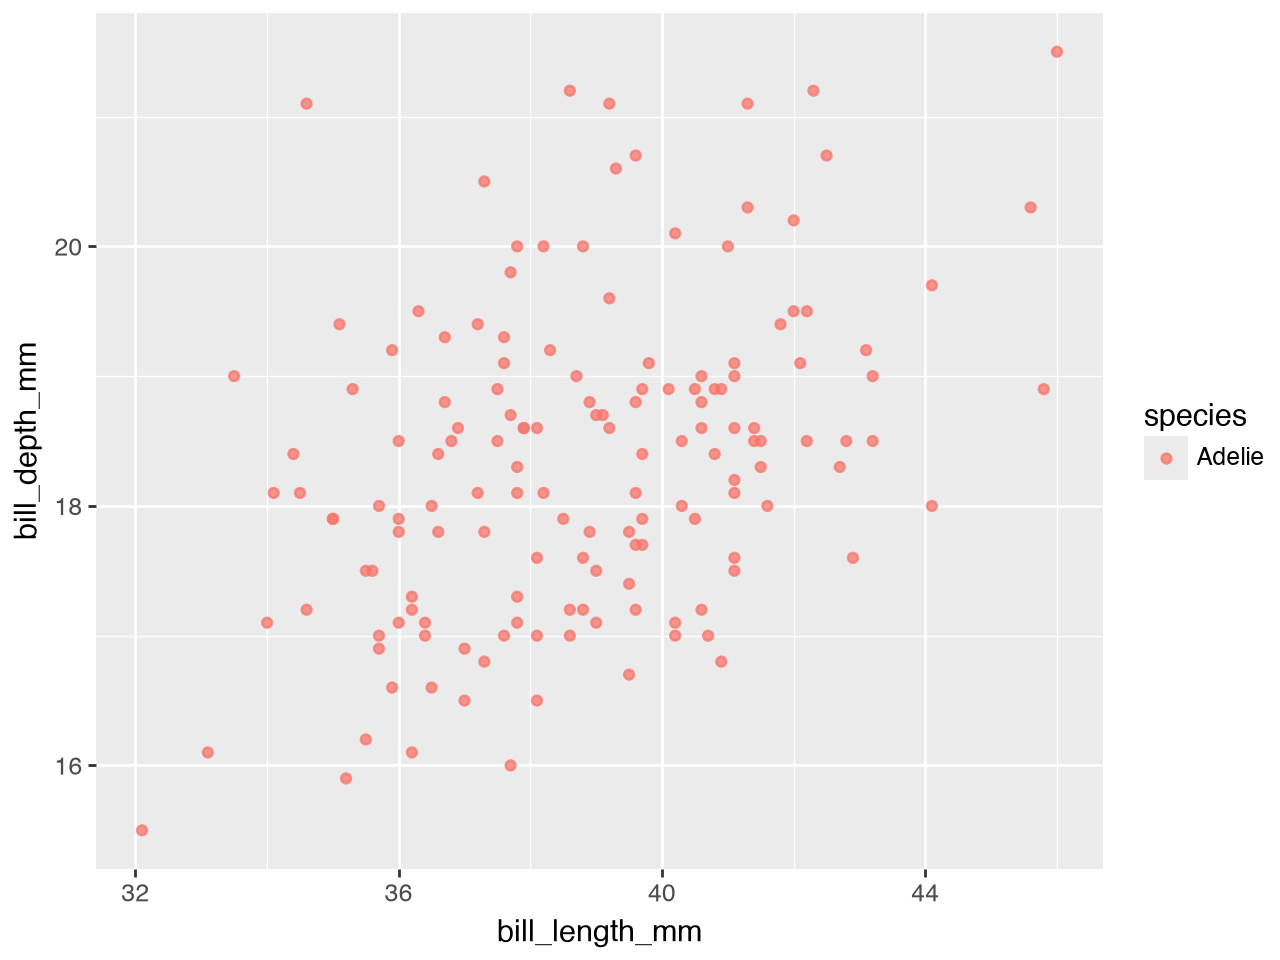

In [3]:
# Species only: all Adelie penguins.
plot_penguins_dynamic(species="Adelie")

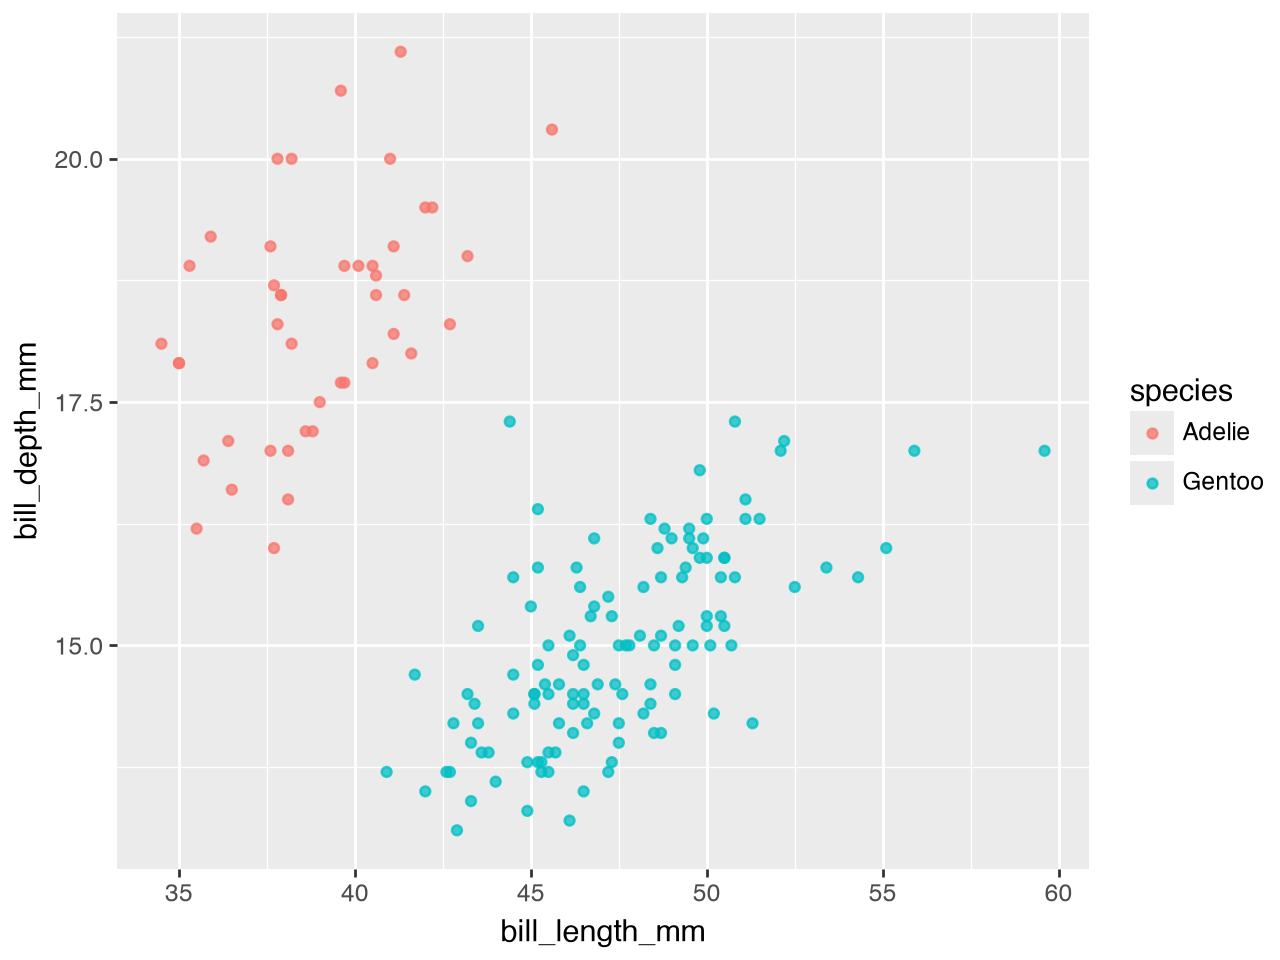

In [4]:
# Island only: all penguins on Biscoe.
plot_penguins_dynamic(island="Biscoe")

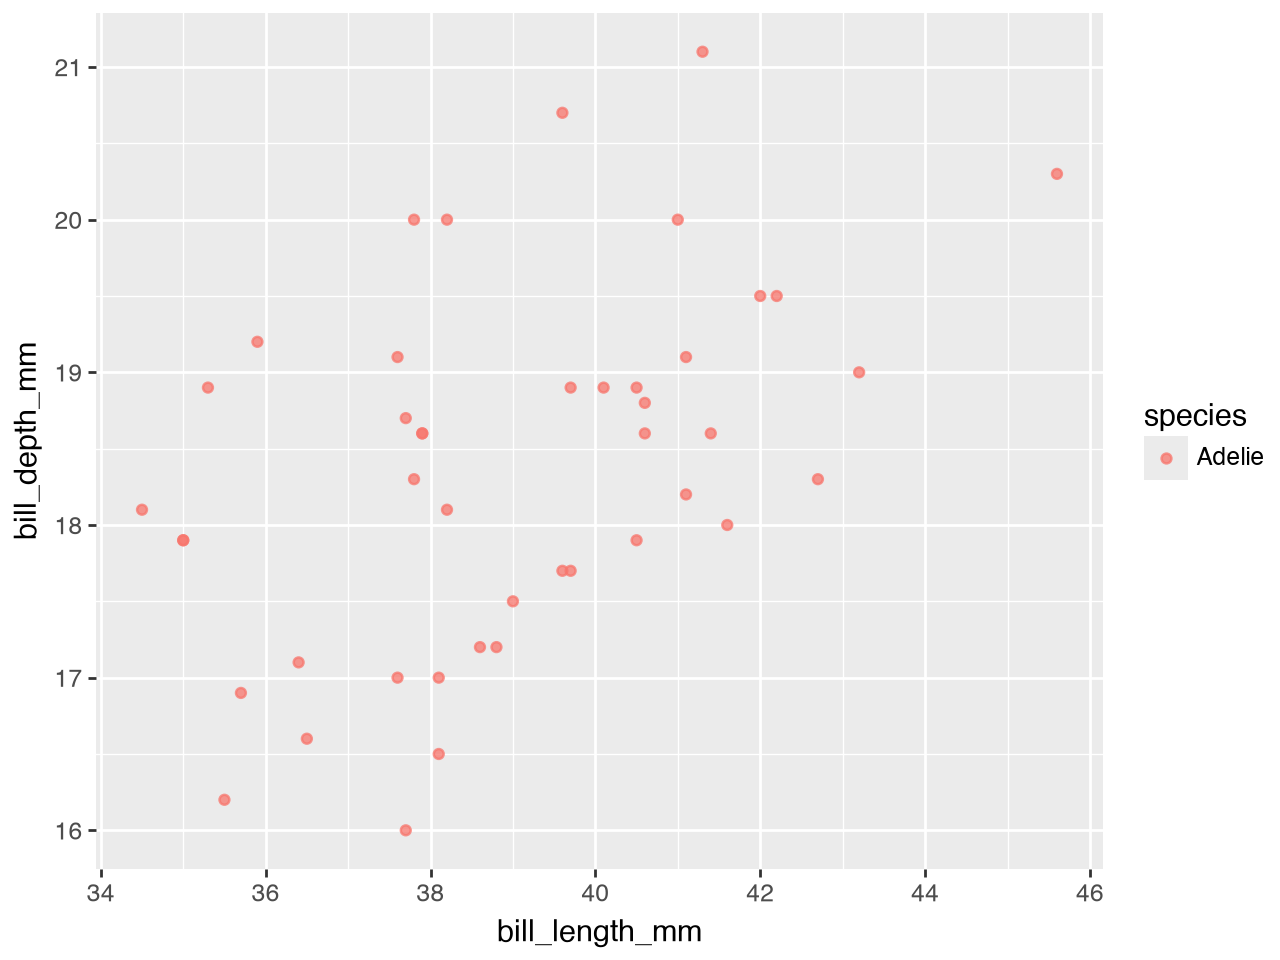

In [5]:
# Both filters: Adelie penguins on Biscoe.
plot_penguins_dynamic(species="Adelie", island="Biscoe")

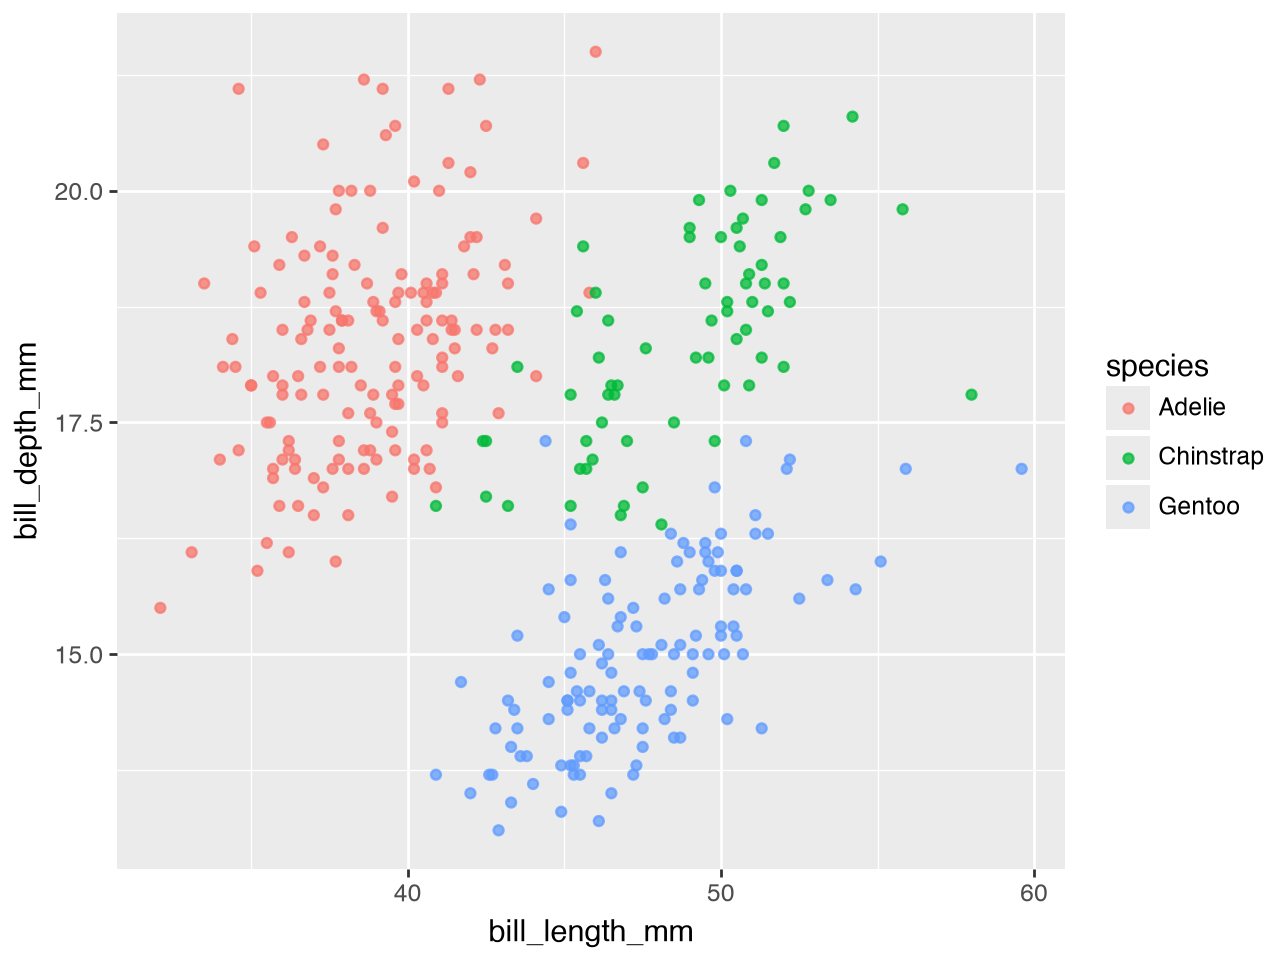

In [6]:
# Neither filter: the whole dataset.
plot_penguins_dynamic()

The explicit version produces the same four plots. The data and plotting tools are passed in each time, so the function can also work with a different compatible dataframe.

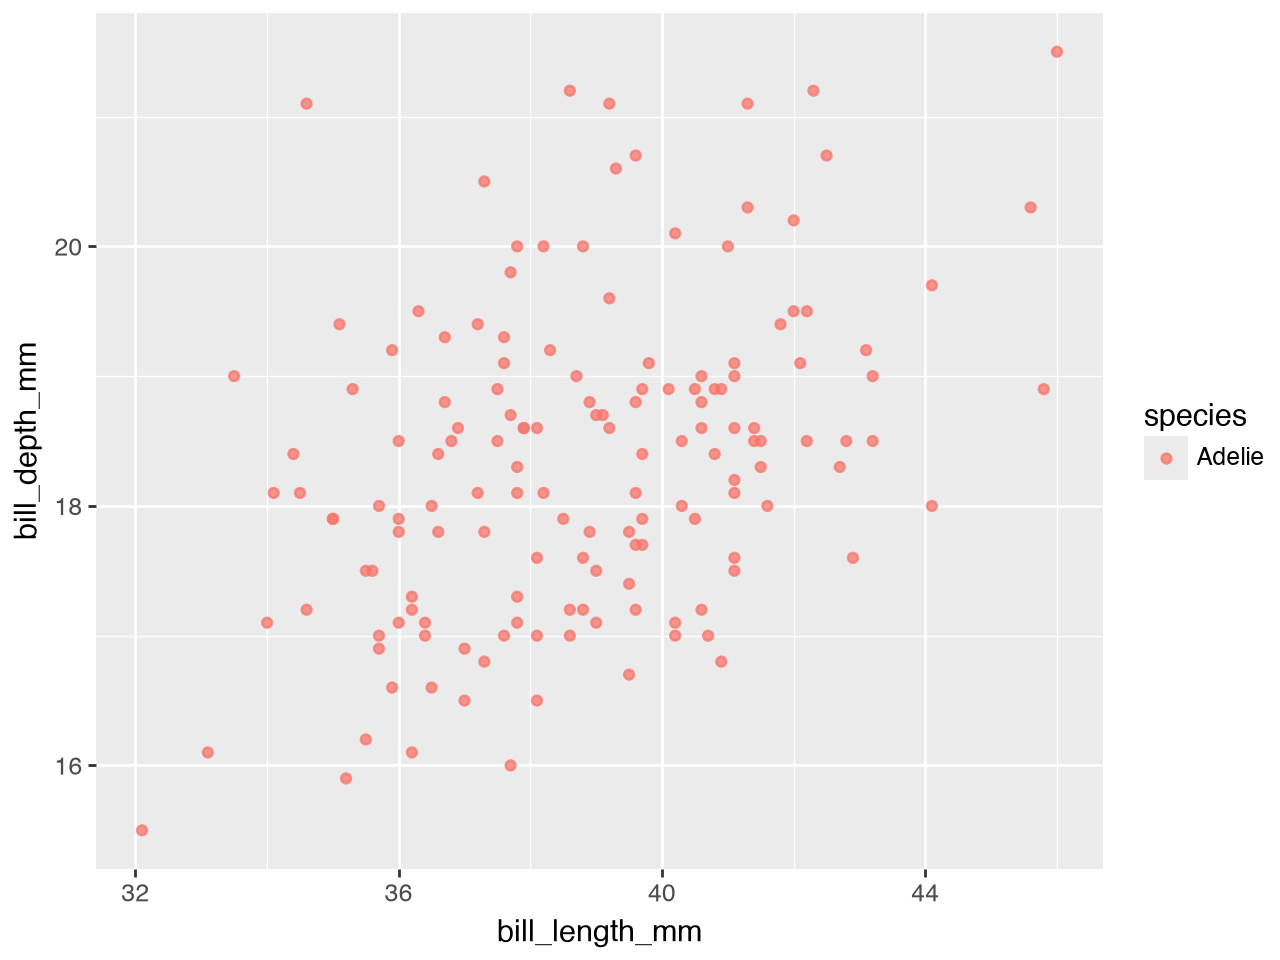

In [7]:
plot_penguins_explicit(penguins, species="Adelie", **plot_tools)

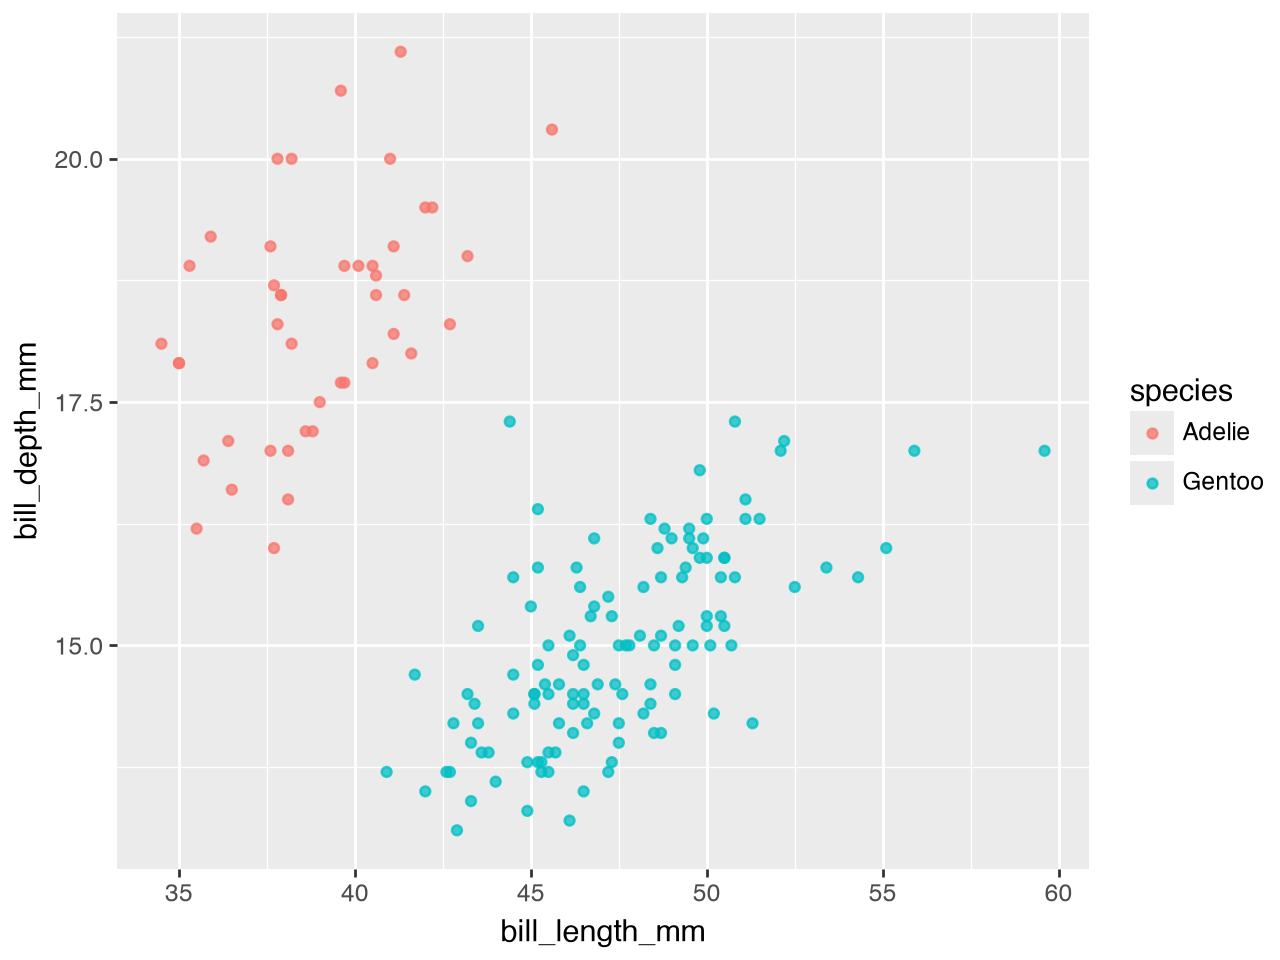

In [8]:
plot_penguins_explicit(penguins, island="Biscoe", **plot_tools)

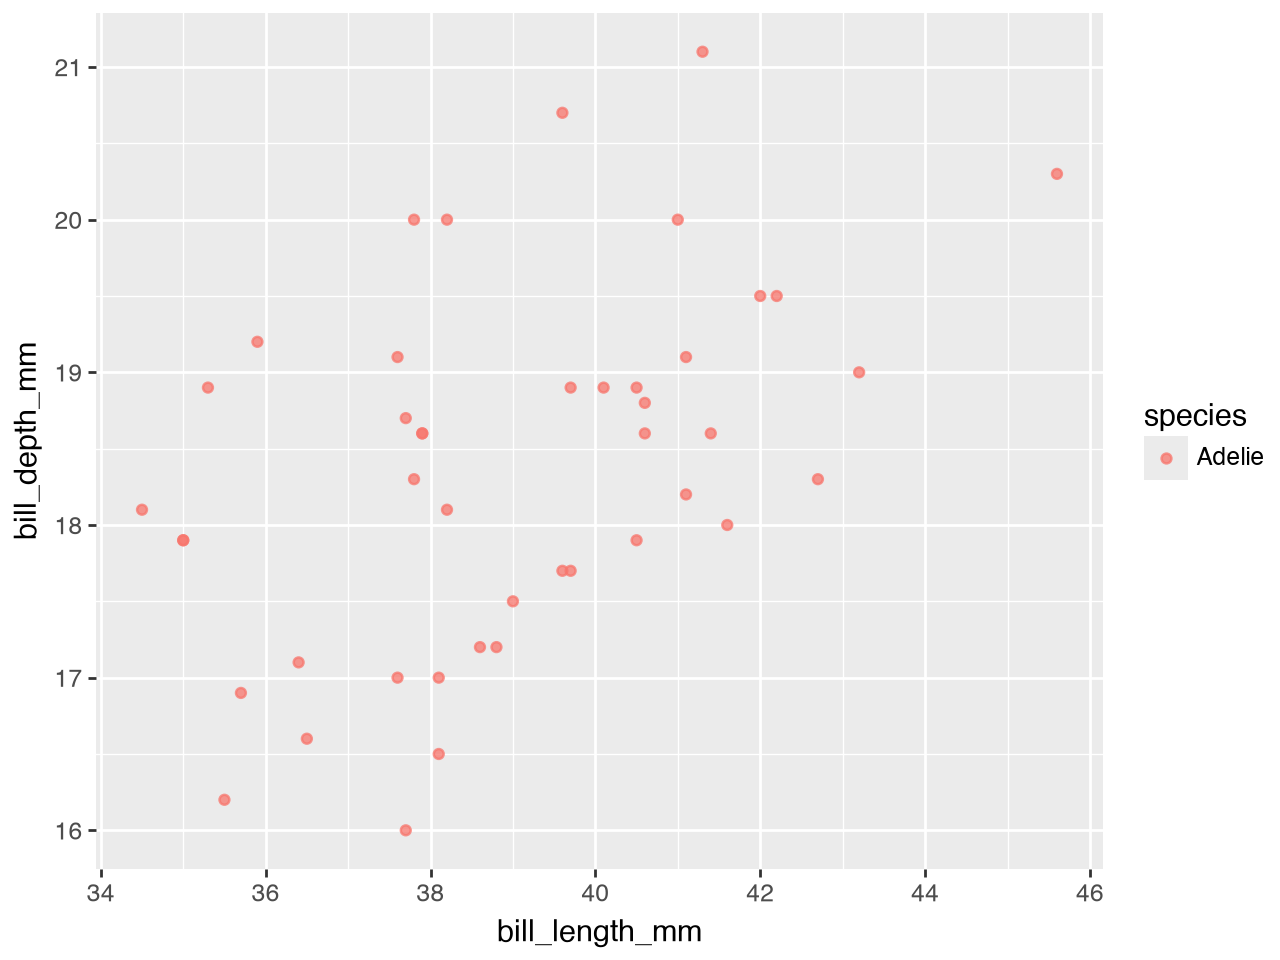

In [9]:
plot_penguins_explicit(penguins, species="Adelie", island="Biscoe", **plot_tools)

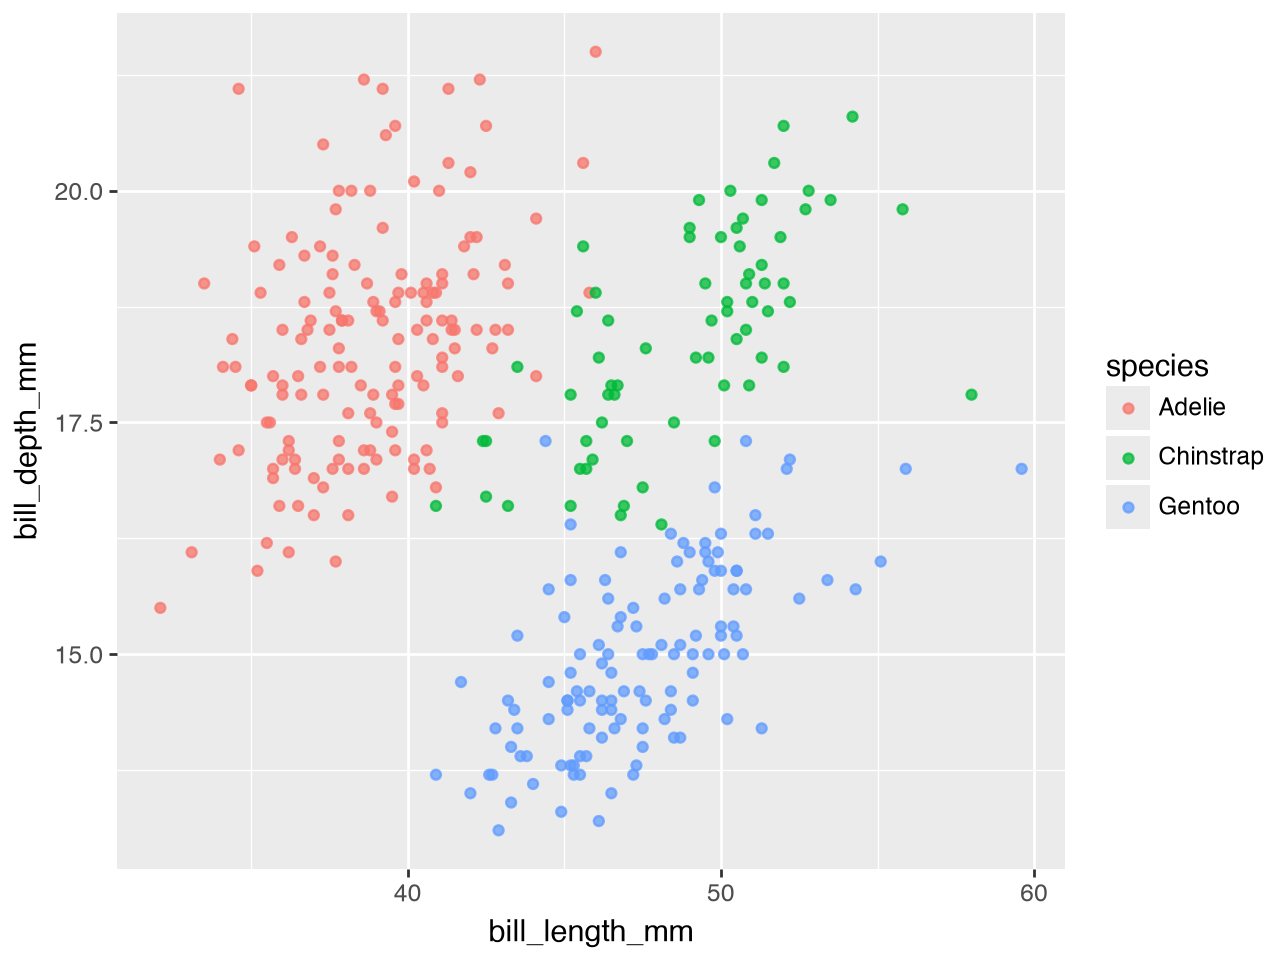

In [10]:
plot_penguins_explicit(penguins, **plot_tools)

In [11]:
# Verify filtering and confirm that both versions select identical rows.
penguins_before = penguins.copy(deep=True)
filter_cases = [
    ("Species only", {"species": "Adelie"}),
    ("Island only", {"island": "Biscoe"}),
    ("Both", {"species": "Adelie", "island": "Biscoe"}),
    ("No filters", {}),
]
filter_summary = []
for description, filters in filter_cases:
    dynamic_plot = plot_penguins_dynamic(**filters)
    explicit_plot = plot_penguins_explicit(penguins, **filters, **plot_tools)
    expected = penguins
    for column, value in filters.items():
        expected = expected.loc[expected[column] == value]
    pd.testing.assert_frame_equal(dynamic_plot.data, expected)
    pd.testing.assert_frame_equal(explicit_plot.data, expected)
    filter_summary.append({
        "Filter": description,
        "Selected rows": len(expected),
        "Plotted complete measurements": len(
            expected.dropna(subset=["bill_length_mm", "bill_depth_mm"])
        ),
    })
pd.testing.assert_frame_equal(penguins, penguins_before)
assert [row["Selected rows"] for row in filter_summary] == [152, 168, 44, 344]
pd.DataFrame(filter_summary)

,Filter,Selected rows,Plotted complete measurements
0,Species only,152,151
1,Island only,168,167
2,Both,44,44
3,No filters,344,342


The selected row counts are 152, 168, 44, and 344. The plotted point counts can be smaller because some penguins have missing measurements. Dynamic lookup is convenient in a short analysis, but replacing or deleting the global `penguins` object changes the function's behavior. The explicit function makes its dependencies visible and allows the caller to choose another dataset.

1. Fill in the necessary code to write a function called `times_seven()`. The function should take a single argument (`x`) and multiply the input by 7.
  + This function should check that the argument is numeric.
  + This function should also excitedly announce (print) *“I love sevens!”* if the argument to the function is a 7.

In [12]:
def times_seven(x):
    """Multiply a numeric scalar by seven; announce an input equal to seven.

    Boolean values and containers are rejected. The supplied exercise uses
    sys.exit for validation, which raises SystemExit on an invalid argument.
    """
    if isinstance(x, (bool, np.bool_)) or not isinstance(x, Number):
        exit("x must be a numeric scalar; booleans and containers are not accepted.")

    if x == 7:
        print("I love sevens!")

    return x * 7

`Number` accepts numeric scalar types, including Python integers, floats, complex numbers, and common NumPy numeric scalars. Booleans are explicitly excluded: `bool` is a subclass of `int`, but a truth value is not the numeric input intended by this exercise. A list is a container, even if all its elements are numbers.

The skeleton's `exit` comes from `sys.exit`. It raises `SystemExit`, so the demonstration and unit tests catch that exception when checking invalid inputs.

2. Write and run some *unit tests* for your `times_seven` function.  What happens if the input to the function is `[1, 3, 5, 7]`?

In [13]:
import io
import unittest
from contextlib import redirect_stdout
from decimal import Decimal
from fractions import Fraction


class TestTimesSeven(unittest.TestCase):
    def test_ordinary_numeric_inputs(self):
        examples = [
            (0, 0),
            (1, 7),
            (-3, -21),
            (2.5, 17.5),
            (1 + 2j, 7 + 14j),
            (np.int64(3), 21),
            (np.float64(1.5), 10.5),
            (Decimal("1.25"), Decimal("8.75")),
            (Fraction(1, 2), Fraction(7, 2)),
        ]
        for value, expected in examples:
            with self.subTest(value=value):
                with redirect_stdout(io.StringIO()) as output:
                    result = times_seven(value)
                self.assertEqual(result, expected)
                self.assertEqual(output.getvalue(), "")

    def test_seven_prints_exact_message_and_returns_49(self):
        for value in [7, 7.0, np.int64(7), np.float64(7), 7 + 0j]:
            with self.subTest(value=value):
                with redirect_stdout(io.StringIO()) as output:
                    result = times_seven(value)
                self.assertEqual(result, 49)
                self.assertEqual(output.getvalue(), "I love sevens!\n")

    def test_invalid_inputs_raise_system_exit(self):
        invalid_inputs = [
            "7", None, True, False, np.bool_(True),
            [1, 3, 5, 7], (1, 3), {"x": 7}, np.array([1, 3, 5, 7]),
        ]
        for value in invalid_inputs:
            with self.subTest(value=repr(value)):
                with redirect_stdout(io.StringIO()) as output:
                    with self.assertRaises(SystemExit) as caught:
                        times_seven(value)
                self.assertEqual(
                    caught.exception.code,
                    "x must be a numeric scalar; booleans and containers are not accepted.",
                )
                self.assertEqual(output.getvalue(), "")

    def test_argument_is_required_and_only_one_is_accepted(self):
        with self.assertRaises(TypeError):
            times_seven()
        with self.assertRaises(TypeError):
            times_seven(1, 2)


suite = unittest.defaultTestLoader.loadTestsFromTestCase(TestTimesSeven)
test_result = unittest.TextTestRunner(verbosity=2).run(suite)
assert test_result.wasSuccessful(), "times_seven unit tests failed"

test_argument_is_required_and_only_one_is_accepted (__main__.TestTimesSeven.test_argument_is_required_and_only_one_is_accepted) ... 

ok


test_invalid_inputs_raise_system_exit (__main__.TestTimesSeven.test_invalid_inputs_raise_system_exit) ... 

ok


test_ordinary_numeric_inputs (__main__.TestTimesSeven.test_ordinary_numeric_inputs) ... 

ok


test_seven_prints_exact_message_and_returns_49 (__main__.TestTimesSeven.test_seven_prints_exact_message_and_returns_49) ... 

ok


----------------------------------------------------------------------
Ran 4 tests in 0.001s

OK


In [14]:
# Show the requested list input without terminating the notebook.
list_input = [1, 3, 5, 7]
try:
    times_seven(list_input)
except SystemExit as error:
    print(f"times_seven({list_input}) -> SystemExit: {error}")

print("Python list repetition without validation:", list_input * 7)
print("Elementwise multiplication if desired:", [value * 7 for value in list_input])

times_seven([1, 3, 5, 7]) -> SystemExit: x must be a numeric scalar; booleans and containers are not accepted.
Python list repetition without validation: [1, 3, 5, 7, 1, 3, 5, 7, 1, 3, 5, 7, 1, 3, 5, 7, 1, 3, 5, 7, 1, 3, 5, 7, 1, 3, 5, 7]
Elementwise multiplication if desired: [7, 21, 35, 49]


For `[1, 3, 5, 7]`, `times_seven` raises `SystemExit` with the validation message; it does not print the excited announcement. The list itself is not a numeric scalar.

Without validation, Python's `list * 7` repeats the entire list seven times, producing 28 elements. It does not multiply each item. A list comprehension produces the elementwise result `[7, 21, 35, 49]`.

3. Consider the following function:

In [15]:
def add_or_subtract(first_num, second_num = 2, type = "add"):

  if (type == "add"):
    res = first_num + second_num
  elif (type == "subtract"):
    res = first_num - second_num
  else:
    exit("Please choose `add` or `subtract` as the type.")

  return res

**Without running the code**, predict if the following will produce:

a. 1

b. -1

c. 30

d. An error defined by the function `add_or_subtract()`

e. An error defined in a different function, which is called inside the `add_or_subtract()` function

**Predictions, made before evaluating the three calls:**

| Call | Choice | Predicted outcome and reason |
| --- | --- | --- |
| `add_or_subtract(5, 6, type="subtract")` | **b** | `5 - 6` returns **-1**. |
| `add_or_subtract("orange")` | **e** | The default `second_num` is `2`; Python cannot add a string and an integer, so the addition operation raises a **TypeError**. |
| `add_or_subtract(5, 6, type="multiply")` | **d** | The unsupported operation reaches the function's `else` branch, which calls `exit` with its custom message and raises **SystemExit**. |

For the second call, choice **e** represents an error originating from Python's addition behavior rather than an explicit validation branch in `add_or_subtract`. More precisely, this error occurs while evaluating the `+` operator; the function does not explicitly call another arithmetic function.

In [16]:
# Evaluate each supplied call independently so an expected exception in one
# example does not prevent the next example from running.
try:
    subtraction_result = add_or_subtract(5, 6, type="subtract")
    print('add_or_subtract(5, 6, type="subtract") ->', subtraction_result)
except (TypeError, SystemExit) as error:
    print(type(error).__name__ + ":", error)

try:
    add_or_subtract("orange")
except TypeError as error:
    string_error = error
    print('add_or_subtract("orange") -> TypeError:', error)

try:
    add_or_subtract(5, 6, type="multiply")
except SystemExit as error:
    operation_error = error
    print('add_or_subtract(5, 6, type="multiply") -> SystemExit:', error)

assert subtraction_result == -1
assert isinstance(string_error, TypeError)
assert isinstance(operation_error, SystemExit)
assert str(operation_error) == "Please choose `add` or `subtract` as the type."

add_or_subtract(5, 6, type="subtract") -> -1
add_or_subtract("orange") -> TypeError: can only concatenate str (not "int") to str
add_or_subtract(5, 6, type="multiply") -> SystemExit: Please choose `add` or `subtract` as the type.


All three observations match the predictions. Neither **a** (`1`) nor **c** (`30`) is produced by these calls. The supplied `add_or_subtract` definition is unchanged.

4. Consider the following code:

In [17]:
first_num  = 5
second_num = 3

result = 8

result = add_or_subtract(first_num, second_num = 4)

result_2 = add_or_subtract(first_num)

In [18]:
result

9

In [19]:
# Inspect globals() while displaying only the four names in this question.
# The full mapping also contains imported modules, functions, and test objects.
global_environment = globals()
{name: global_environment[name]
 for name in ("first_num", "second_num", "result", "result_2")}

{'first_num': 5, 'second_num': 3, 'result': 9, 'result_2': 7}


In your Global Environment, what is the value of...

a. `first_num`

b. `second_num`

c. `result`

d. `result_2`

| Global variable | Final value | Explanation |
| --- | ---: | --- |
| a. `first_num` | **5** | It is assigned `5` and never reassigned. |
| b. `second_num` | **3** | The global assignment stays `3`; `second_num=4` is a function argument, not a global reassignment. |
| c. `result` | **9** | The initial `8` is overwritten by the returned value `5 + 4`. |
| d. `result_2` | **7** | Omitting the second argument uses the function's default `second_num=2`, so the call returns `5 + 2`. |

Each function call creates a local scope. Its parameters `first_num` and `second_num`, and its local `res`, belong to that scope. The global `second_num=3` does not replace the default argument `2`, and passing `second_num=4` does not change the global variable. The caller's assignments to `result` and `result_2` put the returned values in the global environment.

In [20]:
# Confirm the four requested global values.
expected_global_values = {
    "first_num": 5,
    "second_num": 3,
    "result": 9,
    "result_2": 7,
}
actual_global_values = {name: globals()[name] for name in expected_global_values}
assert actual_global_values == expected_global_values
print("All requested global values verified:", actual_global_values)

All requested global values verified: {'first_num': 5, 'second_num': 3, 'result': 9, 'result_2': 7}
